# Khmer Text Emotion Classification — Pilot Implementation
**ITM 454 002 · Team: What to do?? · Chanveasna CHEN and Youleng GHOV**

This pilot uses the **three supplied Parquet files**, audits the complete local dataset, and trains a character TF–IDF + linear SVM on a reproducible, bounded sample of unique texts. It also provides XLM-R fine-tuning on **exactly the same saved splits**.

**Dataset correction:** the actual labels are `angry, fear, happy, lonely, neutral, sad, stress`. There is no `surprise` label in these files. We retain `lonely`; it must not be silently renamed to `surprise`. Revise the proposal accordingly. All three filenames start with `train`: they are shards, not predefined evaluation splits.

**Pilot questions:** Can we clean and split the real data without exact-text leakage? How strong is a character baseline? Which emotions are confused? Can an XLM-R run improve macro F1 on the same data? The proposed 80% accuracy is a target, not an assumed result.

Run cells in order with this folder as the working directory. The default run audits all rows but samples at most 1,000 unique texts per class; it runs the SVM locally. XLM-R is disabled by default because it needs additional packages, a pretrained model download and substantially more compute. Enable it in the configuration for a GPU run. An unexecuted transformer is always reported as **not run**, never as a measured comparison.


## 1. Environment and reproducibility
Install the core dependencies into your notebook environment if needed:
```python
%pip install pandas pyarrow numpy scipy scikit-learn matplotlib joblib
```
For the optional transformer cells:
```python
%pip install 'torch>=2.2' 'transformers>=4.46,<5' 'datasets>=3,<5' 'accelerate>=1,<2' sentencepiece
```
Restart the kernel after installation. No dataset upload or Hugging Face dataset login is needed: data is read locally. Artifacts remain in `artifacts/`. The database is rebuilt on each run so changed input files cannot reuse a stale audit.


In [1]:
from pathlib import Path
from collections import Counter
from functools import lru_cache
import hashlib, json, re, sqlite3, time, unicodedata, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)
import joblib

SEED = 42
PER_CLASS = 1000                 # bounded pilot; enlarge only for a new experiment
RUN_XLMR = False                # set True before Run All for the transformer experiment
XLMR_EPOCHS = 2
MAX_LENGTH = 128
MODEL_NAME = 'FacebookAI/xlm-roberta-base'
DATA_DIR = Path.cwd()
OUT = DATA_DIR / 'artifacts'
OUT.mkdir(exist_ok=True)
FILES = [DATA_DIR / f'train-{i:05d}-of-00003.parquet' for i in range(3)]
assert all(p.is_file() for p in FILES), 'Run from the folder containing all three Parquet files.'
LABELS = ['angry', 'fear', 'happy', 'lonely', 'neutral', 'sad', 'stress']
label2id = {label: i for i, label in enumerate(LABELS)}
id2label = {i: label for label, i in label2id.items()}
versions = {p: metadata.version(p) for p in ['pandas','pyarrow','numpy','scikit-learn','matplotlib']}
print('Python:', platform.python_version(), '| Packages:', versions)
manifest = []
for path in FILES:
    parquet = pq.ParquetFile(path)
    assert {'id', 'text', 'label'} <= set(parquet.schema_arrow.names)
    with path.open('rb') as f:
        digest = hashlib.file_digest(f, 'sha256').hexdigest()
    manifest.append({'file': path.name, 'rows': parquet.metadata.num_rows,
                     'bytes': path.stat().st_size, 'sha256': digest})
display(pd.DataFrame(manifest))


Python: 3.13.7 | Packages: {'pandas': '3.0.5', 'pyarrow': '25.0.1', 'numpy': '2.5.3', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}


,file,rows,bytes,sha256
0,train-00000-of-00003.parquet,1395030,47309910,c0c1b968e27608bf025c64add0f31b682e0df379516ed6...
1,train-00001-of-00003.parquet,1395030,32843138,a09d086a9a83ac9e8ac3c0520e6e029b330f5e38ec7170...
2,train-00002-of-00003.parquet,1395030,80645559,fc4e1ba829ea5870338e4dddb5198022f6d44e45661b2d...


## 2. Full-data audit and conservative cleaning
NFC normalization preserves Khmer combining marks. Zero-width separators and control characters become spaces, whitespace is collapsed, and punctuation, digits and emoji are retained because they can carry emotion. We reject missing/non-string/empty text, missing IDs, invalid labels and text with no Khmer character; each rejection is counted under its first failing rule.

The SQLite index processes batches rather than loading 4.2 million rows into RAM. The deduplication key ignores whitespace after normalization, conservatively grouping spacing variants. All copies of a key with contradictory emotion labels are excluded. Every surviving key appears only once before sampling and splitting. IDs are retained for provenance, but text keys define split identity; IDs are not model features. Counts refer to rows unless explicitly described as keys.


In [2]:
@lru_cache(maxsize=50000)
def clean_text(text):
    text = unicodedata.normalize('NFC', text)
    text = ''.join(' ' if unicodedata.category(ch) in {'Cc', 'Cf'} else ch for ch in text)
    return re.sub(r'\s+', ' ', text).strip()

def text_key(text):
    return re.sub(r'\s+', '', text)

khmer = re.compile(r'[\u1780-\u17FF]')
db = sqlite3.connect(OUT / 'audit.sqlite')
db.execute('DROP TABLE IF EXISTS texts')
db.execute('CREATE TABLE texts (key TEXT PRIMARY KEY, text TEXT, mask INTEGER, n INTEGER, source_id TEXT, source_file TEXT)')
insert_sql = """INSERT INTO texts VALUES (?, ?, ?, ?, ?, ?)
ON CONFLICT(key) DO UPDATE SET mask = texts.mask | excluded.mask, n = texts.n + excluded.n"""
rejected, observed_labels, shard_labels = Counter(), Counter(), []
raw_rows = 0
start = time.perf_counter()
for path in FILES:
    shard_counter = Counter()
    for batch in pq.ParquetFile(path).iter_batches(batch_size=50000, columns=['id','text','label']):
        rows = batch.to_pydict()
        grouped = {}
        for ident, text, label in zip(rows['id'], rows['text'], rows['label']):
            raw_rows += 1
            label = label.strip().lower() if isinstance(label, str) else '<missing>'
            observed_labels[label] += 1
            shard_counter[label] += 1
            if ident is None:
                rejected['missing_id'] += 1; continue
            if not isinstance(text, str):
                rejected['missing_or_nonstring_text'] += 1; continue
            if label not in label2id:
                rejected['unexpected_label'] += 1; continue
            normalized = clean_text(text)
            if not normalized:
                rejected['empty_after_cleaning'] += 1; continue
            if not khmer.search(normalized):
                rejected['no_khmer_character'] += 1; continue
            key = text_key(normalized)
            mask = 1 << label2id[label]
            if key in grouped:
                grouped[key][2] |= mask
                grouped[key][3] += 1
            else:
                grouped[key] = [key, normalized, mask, 1, str(ident), path.name]
        db.executemany(insert_sql, grouped.values())
        db.commit()
    shard_labels.append({'file': path.name, **shard_counter})
    print(f'Finished {path.name}: {raw_rows:,} rows scanned', flush=True)

unique_keys, valid_rows = db.execute('SELECT COUNT(*), COALESCE(SUM(n),0) FROM texts').fetchone()
conflict_keys, conflict_rows = db.execute(
    'SELECT COUNT(*), COALESCE(SUM(n),0) FROM texts WHERE (mask & (mask - 1)) != 0').fetchone()
audit = {'raw_rows': raw_rows, 'rejected': dict(rejected), 'valid_rows_before_dedup': valid_rows,
         'unique_normalized_keys': unique_keys, 'duplicate_excess_rows': valid_rows - unique_keys,
         'conflicting_keys_excluded': conflict_keys, 'rows_in_conflicting_keys': conflict_rows,
         'eligible_unique_texts': unique_keys - conflict_keys, 'raw_label_counts': dict(observed_labels)}
assert raw_rows == valid_rows + sum(rejected.values())
assert set(observed_labels) == set(LABELS), 'Label inventory changed: review the configuration.'
print(json.dumps(audit, indent=2))
print(f'Audit duration: {time.perf_counter() - start:.1f} seconds')
display(pd.DataFrame(shard_labels).set_index('file').fillna(0).astype(int))
(OUT / 'data_audit.json').write_text(json.dumps(audit, indent=2))


Finished train-00000-of-00003.parquet: 1,395,030 rows scanned
Finished train-00001-of-00003.parquet: 2,790,060 rows scanned
Finished train-00002-of-00003.parquet: 4,185,090 rows scanned
{
  "raw_rows": 4185090,
  "rejected": {},
  "valid_rows_before_dedup": 4185090,
  "unique_normalized_keys": 1356385,
  "duplicate_excess_rows": 2828705,
  "conflicting_keys_excluded": 0,
  "rows_in_conflicting_keys": 0,
  "eligible_unique_texts": 1356385,
  "raw_label_counts": {
    "fear": 566165,
    "happy": 566485,
    "sad": 566074,
    "stress": 781519,
    "neutral": 571889,
    "angry": 566549,
    "lonely": 566409
  }
}
Audit duration: 63.2 seconds


,fear,happy,sad,stress,neutral,angry,lonely
file,,,,,,,
train-00000-of-00003.parquet,199288,199425,199040,199320,199380,199204,199373
train-00001-of-00003.parquet,199222,199122,199093,199398,199426,199422,199347
train-00002-of-00003.parquet,167655,167938,167941,382801,173083,167923,167689


433

## 3. Reproducible pilot and common splits
Uniform reservoir sampling selects up to 1,000 **unique** eligible texts per class from the complete index, using a fixed seed and deterministic key order. This intentionally balances the pilot where possible: its accuracy does not estimate the original row-frequency distribution. The 70/15/15 train/validation/test split is stratified. Test labels are reserved for final evaluation; validation macro F1 selects the SVM hyperparameter and XLM-R checkpoint.


,raw_rows,eligible_unique,train,validation,test
angry,566549,162303,700,150,150
fear,566165,162117,700,150,150
happy,566485,162879,700,150,150
lonely,566409,162170,700,150,150
neutral,571889,167179,700,150,150
sad,566074,162520,700,150,150
stress,781519,377217,700,150,150


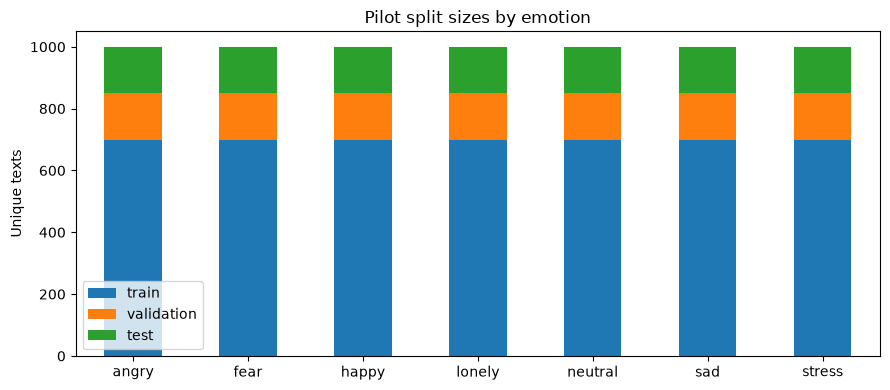

,text,label,source_file
0,ខ្ញុំទទួលបានកាដូដែលខ្ញុំស្រលាញ់បំផុត។ (2737),happy,train-00001-of-00003.parquet
1,ខ្ញុំបារម្ភនិងខ្លាចក្រែងមានរឿងមិនល្អកើតឡើង។ (5...,fear,train-00001-of-00003.parquet
2,ពេលឃើញសត្វសាហាវនោះ ខ្ញុំតក់ស្លុតខ្លាំងណាស់។ (1...,fear,train-00001-of-00003.parquet
3,ហេតុអ្វីបានជាពួកគេមិនគោរពសិទ្ធិអ្នកដទៃទាល់តែសោ...,angry,train-00001-of-00003.parquet
4,កុំមកនិយាយជាមួយខ្ញុំទៀតអី ខ្ញុំកំពុងខឹងហើយ។ (7...,angry,train-00001-of-00003.parquet
7,បេះដូងខ្ញុំឈឺចាប់ពេលឃើញគេចាកចេញ។ (16628),sad,train-00001-of-00003.parquet
8,មេឃថ្ងៃនេះស្រឡះល្អធម្មតា។ (19204),neutral,train-00001-of-00003.parquet
9,ពេលខ្លះខ្ញុំមានអារម្មណ៍ថាពិបាកចិត្ត និងមានសម្ព...,stress,train-00002-of-00003.parquet
10,ខ្ញុំសប្បាយចិត្តណាស់ថ្ងៃនេះបានជួបជុំគ្រួសារ។ (...,happy,train-00001-of-00003.parquet
13,បេះដូងខ្ញុំឈឺចាប់ពេលឃើញគេចាកចេញ។ (19973),sad,train-00001-of-00003.parquet


Text character lengths: {'count': 7000.0, 'mean': 97.9, 'std': 108.0, 'min': 31.0, '25%': 47.0, '50%': 52.0, '75%': 62.0, 'max': 433.0}


In [3]:
rng = np.random.default_rng(SEED)
reservoirs = {label: [] for label in LABELS}
seen = Counter()
for key, text, mask, source_id, source_file, copies in db.execute(
    'SELECT key,text,mask,source_id,source_file,n FROM texts WHERE (mask & (mask - 1)) = 0 ORDER BY key'):
    label = id2label[int(mask).bit_length() - 1]
    seen[label] += 1
    row = {'text_key': key, 'text': text, 'label': label, 'source_id': source_id,
           'source_file': source_file, 'source_copies': copies}
    bucket = reservoirs[label]
    if len(bucket) < PER_CLASS:
        bucket.append(row)
    else:
        slot = int(rng.integers(seen[label]))
        if slot < PER_CLASS:
            bucket[slot] = row
pilot = pd.DataFrame([row for label in LABELS for row in reservoirs[label]])
assert all(len(reservoirs[label]) >= 20 for label in LABELS), 'Too few unique texts for a stable pilot split.'
train_df, heldout = train_test_split(pilot, test_size=0.30, stratify=pilot.label, random_state=SEED)
val_df, test_df = train_test_split(heldout, test_size=0.50, stratify=heldout.label, random_state=SEED)
splits = {'train': train_df.reset_index(drop=True), 'validation': val_df.reset_index(drop=True),
          'test': test_df.reset_index(drop=True)}
train_df, val_df, test_df = splits.values()
key_sets = [set(frame.text_key) for frame in splits.values()]
assert all(key_sets[i].isdisjoint(key_sets[j]) for i in range(3) for j in range(i + 1, 3))
assert sum(map(len, splits.values())) == len(pilot) == pilot.text_key.nunique()
for name, frame in splits.items():
    frame.to_parquet(OUT / f'{name}.parquet', index=False)
counts = pd.DataFrame({'raw_rows': pd.Series(observed_labels), 'eligible_unique': pd.Series(seen),
                       **{name: frame.label.value_counts() for name, frame in splits.items()}}).reindex(LABELS)
display(counts)
counts.to_csv(OUT / 'class_distribution.csv')
counts[['train','validation','test']].plot.bar(stacked=True, figsize=(9,4), title='Pilot split sizes by emotion')
plt.ylabel('Unique texts'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
display(train_df.groupby('label', sort=True).head(2)[['text','label','source_file']])
print('Text character lengths:', pilot.text.str.len().describe().round(1).to_dict())
config = {'seed': SEED, 'per_class_cap': PER_CLASS, 'labels': LABELS, 'splits': {k: len(v) for k,v in splits.items()},
          'versions': versions, 'files': manifest, 'model': MODEL_NAME, 'xlmr_enabled': RUN_XLMR,
          'xlmr_epochs': XLMR_EPOCHS, 'max_length': MAX_LENGTH}
(OUT / 'run_config.json').write_text(json.dumps(config, indent=2))
db.close()
clean_text.cache_clear()


## 4. Character TF–IDF + linear SVM
Khmer does not reliably delimit words with spaces. Character 2–5-grams therefore provide a segmentation-free baseline. TF–IDF is fit only on training text; `C` is selected from a small grid using validation macro F1. We keep the selected model trained on the training split (no train+validation refit), matching the transformer comparison. A majority-class dummy model supplies a lower baseline. No IDs, filenames or repetition counts enter the features.


In [4]:
def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average='macro', zero_division=0)
    _, _, weighted_f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average='weighted', zero_division=0)
    return {'accuracy': accuracy_score(y_true, y_pred), 'precision_macro': p,
            'recall_macro': r, 'f1_macro': f, 'f1_weighted': weighted_f}

vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2,5), min_df=2,
                            max_features=80000, sublinear_tf=True, dtype=np.float32)
X_train = vectorizer.fit_transform(train_df.text)
X_val = vectorizer.transform(val_df.text)
validation_rows = []
best_score, best_svm = -1, None
svm_start = time.perf_counter()
for c in [0.1, 1.0, 10.0]:
    candidate = LinearSVC(C=c, class_weight='balanced', dual='auto', random_state=SEED, max_iter=5000)
    candidate.fit(X_train, train_df.label)
    scores = metrics(val_df.label, candidate.predict(X_val))
    validation_rows.append({'C': c, **scores})
    if scores['f1_macro'] > best_score:
        best_score, best_svm = scores['f1_macro'], candidate
svm_seconds = time.perf_counter() - svm_start
svm = Pipeline([('tfidf', vectorizer), ('classifier', best_svm)])
display(pd.DataFrame(validation_rows))
print('Selected C:', best_svm.C, '| Features:', X_train.shape[1])
joblib.dump(svm, OUT / 'svm.joblib')


,C,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,0.1,0.992381,0.992431,0.992381,0.992384,0.992384
1,1.0,0.995238,0.995257,0.995238,0.995238,0.995238
2,10.0,0.996190,0.996215,0.996190,0.996190,0.996190


Selected C: 10.0 | Features: 38584


['/Users/thisisnotleng/Desktop/AUPP/NLP/Pilot Test Final/artifacts/svm.joblib']

## 5. Optional XLM-R fine-tuning
Set `RUN_XLMR=True` in section 1 and rerun in an environment with the optional dependencies. This is real sequence-classification fine-tuning of `FacebookAI/xlm-roberta-base`, not zero-shot inference. The randomly initialized seven-class head is learned from training labels. Dynamic padding, gradient accumulation and checkpointing limit memory use. Two epochs are a feasibility pilot, not a claim of convergence; longer runs and learning-rate tuning belong in the final project.

A CUDA GPU is recommended; Apple MPS and CPU execution are supported by Trainer but may be slow or memory constrained. Reduce batch size or sequence length if needed and record the change. Inputs longer than 128 tokenizer tokens are truncated; training/validation truncation rates are printed. XLM-R tokenization differs from character length.

Implementation references: [Hugging Face text classification](https://huggingface.co/docs/transformers/main/tasks/sequence_classification), [XLM-R base model](https://huggingface.co/FacebookAI/xlm-roberta-base). The code targets the Transformers 4.x API pinned above.


In [5]:
trainer = None
xlmr_seconds = None
if RUN_XLMR:
    import torch
    from datasets import Dataset
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                              TrainingArguments, Trainer, set_seed)
    set_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    tokenized = {}
    for name, frame in splits.items():
        dataset = Dataset.from_dict({'text': frame.text.tolist(), 'labels': frame.label.map(label2id).tolist()})
        tokenized[name] = dataset.map(lambda batch: tokenizer(batch['text'], truncation=True, max_length=MAX_LENGTH),
                                      batched=True, remove_columns=['text'])
    for name in ['train', 'validation']:
        lengths = [len(ids) for ids in tokenizer(splits[name].text.tolist(), truncation=False)['input_ids']]
        print(f'{name} token truncation rate: {np.mean(np.array(lengths) > MAX_LENGTH):.1%}')
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id)
    def transformer_metrics(prediction):
        logits = prediction.predictions
        if isinstance(logits, tuple):
            logits = logits[0]
        return metrics([id2label[int(i)] for i in prediction.label_ids],
                       [id2label[int(i)] for i in np.argmax(logits, axis=-1)])
    args = TrainingArguments(
        output_dir=str(OUT / 'xlmr_checkpoints'), num_train_epochs=XLMR_EPOCHS,
        learning_rate=2e-5, weight_decay=0.01, warmup_ratio=0.1,
        per_device_train_batch_size=4, per_device_eval_batch_size=8,
        gradient_accumulation_steps=4, gradient_checkpointing=True,
        eval_strategy='epoch', save_strategy='epoch', load_best_model_at_end=True,
        metric_for_best_model='f1_macro', greater_is_better=True, save_total_limit=1,
        fp16=torch.cuda.is_available(), optim='adamw_torch', dataloader_num_workers=0,
        dataloader_pin_memory=torch.cuda.is_available(), report_to='none',
        seed=SEED, data_seed=SEED, logging_steps=50, push_to_hub=False)
    trainer = Trainer(model=model, args=args, train_dataset=tokenized['train'],
                      eval_dataset=tokenized['validation'], processing_class=tokenizer,
                      data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=transformer_metrics)
    start = time.perf_counter()
    trainer.train()
    xlmr_seconds = time.perf_counter() - start
    trainer.save_model(str(OUT / 'xlmr_model'))
    tokenizer.save_pretrained(OUT / 'xlmr_model')
    (OUT / 'xlmr_environment.json').write_text(json.dumps({
        'versions': {p: metadata.version(p) for p in ['torch','transformers','datasets','accelerate']},
        'device': str(trainer.args.device), 'model_commit': getattr(model.config, '_commit_hash', None),
        'training_arguments': args.to_dict()}, indent=2, default=str))
else:
    print('XLM-R NOT RUN. Enable RUN_XLMR and install optional dependencies to measure it.')


XLM-R NOT RUN. Enable RUN_XLMR and install optional dependencies to measure it.


## 6. Final held-out evaluation
Both selected models use the same test rows and class order. Macro precision/recall/F1 weight each emotion equally; weighted F1 reflects this pilot test set's support. We also save per-class reports, confusion matrices and individual predictions. The fixed-seed bootstrap interval reflects test-sample variability only, not variation across training seeds, templates or domains. Do not tune models after inspecting this test set.


Majority baseline


,precision,recall,f1-score,support
angry,0.1429,1.0000,0.2500,150.0000
fear,0.0000,0.0000,0.0000,150.0000
happy,0.0000,0.0000,0.0000,150.0000
lonely,0.0000,0.0000,0.0000,150.0000
neutral,0.0000,0.0000,0.0000,150.0000
sad,0.0000,0.0000,0.0000,150.0000
stress,0.0000,0.0000,0.0000,150.0000
accuracy,0.1429,0.1429,0.1429,0.1429
macro avg,0.0204,0.1429,0.0357,1050.0000
weighted avg,0.0204,0.1429,0.0357,1050.0000


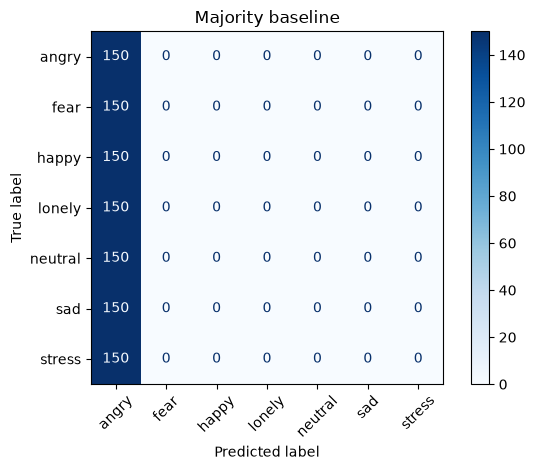

TF-IDF + SVM


,precision,recall,f1-score,support
angry,1.0000,1.0000,1.0000,150.0000
fear,0.9933,0.9933,0.9933,150.0000
happy,0.9933,0.9867,0.9900,150.0000
lonely,0.9934,1.0000,0.9967,150.0000
neutral,1.0000,0.9933,0.9967,150.0000
sad,1.0000,1.0000,1.0000,150.0000
stress,0.9934,1.0000,0.9967,150.0000
accuracy,0.9962,0.9962,0.9962,0.9962
macro avg,0.9962,0.9962,0.9962,1050.0000
weighted avg,0.9962,0.9962,0.9962,1050.0000


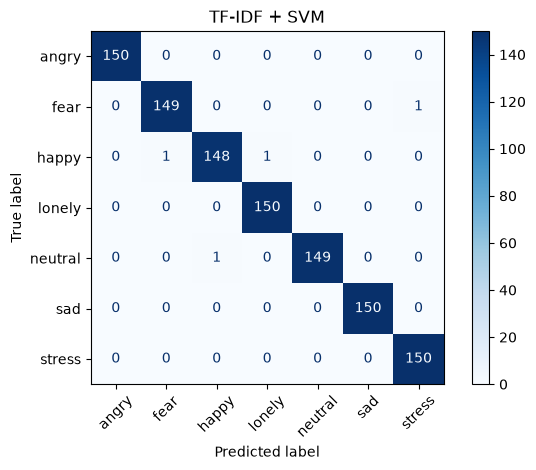

,model,status,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy_ci_low,accuracy_ci_high
0,Majority baseline,measured,0.1429,0.0204,0.1429,0.0357,0.0357,0.1219,0.1657
1,TF-IDF + SVM,measured,0.9962,0.9962,0.9962,0.9962,0.9962,0.9924,0.9990
2,XLM-R,not run,NaN,NaN,NaN,NaN,NaN,NaN,NaN


SVM pilot accuracy: 99.62%; 80% pilot target: met.
This does not establish accuracy on naturally occurring Khmer text.


In [6]:
dummy = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(train_df),1)), train_df.label)
predictions = {
    'Majority baseline': dummy.predict(np.zeros((len(test_df),1))),
    'TF-IDF + SVM': svm.predict(test_df.text)
}
if trainer is not None:
    result = trainer.predict(tokenized['test'])
    predictions['XLM-R'] = np.array([id2label[int(i)] for i in np.argmax(result.predictions, axis=-1)])
rows = []
for name, pred in predictions.items():
    scores = metrics(test_df.label, pred)
    correctness = (test_df.label.to_numpy() == pred).astype(float)
    bootstrap_rng = np.random.default_rng(SEED)
    acc_samples = [bootstrap_rng.choice(correctness, size=len(correctness), replace=True).mean() for _ in range(1000)]
    low, high = np.quantile(acc_samples, [0.025, 0.975])
    rows.append({'model': name, 'status': 'measured', **scores, 'accuracy_ci_low': low, 'accuracy_ci_high': high})
    report = pd.DataFrame(classification_report(test_df.label, pred, labels=LABELS, output_dict=True, zero_division=0)).T
    slug = {'Majority baseline':'dummy', 'TF-IDF + SVM':'svm', 'XLM-R':'xlmr'}[name]
    report.to_csv(OUT / f'{slug}_classification_report.csv')
    print(name); display(report.round(4))
    ConfusionMatrixDisplay.from_predictions(test_df.label, pred, labels=LABELS, xticks_rotation=45, cmap='Blues')
    plt.title(name); plt.tight_layout(); plt.savefig(OUT / f'{slug}_confusion_matrix.png', dpi=150); plt.show()
if trainer is None:
    rows.append({'model':'XLM-R', 'status':'not run'})
comparison = pd.DataFrame(rows)
display(comparison.round(4))
comparison.to_csv(OUT / 'model_comparison.csv', index=False)
prediction_table = test_df.copy()
for name, pred in predictions.items():
    prediction_table[name] = pred
prediction_table.to_parquet(OUT / 'test_predictions.parquet', index=False)
svm_accuracy = accuracy_score(test_df.label, predictions['TF-IDF + SVM'])
print(f'SVM pilot accuracy: {svm_accuracy:.2%}; 80% pilot target: {"met" if svm_accuracy >= 0.8 else "not met"}.')
print('This does not establish accuracy on naturally occurring Khmer text.')


## 7. Leakage diagnostics and error inspection
Exact normalized keys are disjoint by construction, but paraphrases and templates can still cross splits. The diagnostic below measures each test text's closest training-text cosine similarity in the training-fitted TF–IDF space. It is a warning signal, not proof of independence or a new tuning set. Inspect the most similar pairs and errors; for the final project, construct source/template groups **before** splitting and obtain an independently collected, human-reviewed test set. Do not infer the dataset's provenance from high scores alone.


In [7]:
from sklearn.neighbors import NearestNeighbors
neighbors = NearestNeighbors(n_neighbors=1, metric='cosine', algorithm='brute').fit(X_train)
distances, indices = neighbors.kneighbors(vectorizer.transform(test_df.text))
similarity = 1 - distances[:,0]
print(f'Test rows with nearest-train cosine similarity >= 0.95: {np.mean(similarity >= .95):.1%}')
pairs = pd.DataFrame({'test_text': test_df.text, 'test_label': test_df.label,
                      'nearest_train_text': train_df.iloc[indices[:,0]].text.to_numpy(),
                      'nearest_train_label': train_df.iloc[indices[:,0]].label.to_numpy(),
                      'cosine_similarity': similarity}).sort_values('cosine_similarity', ascending=False)
display(pairs.head(10))
pairs.to_parquet(OUT / 'nearest_train_diagnostic.parquet', index=False)
errors = prediction_table[prediction_table.label != prediction_table['TF-IDF + SVM']]
print(f'SVM mistakes: {len(errors)} / {len(test_df)}')
display(errors[['text','label','TF-IDF + SVM']].head(20))
if errors.empty:
    print('No errors in this pilot split; audit template similarity and test on new human-labeled texts.')


Test rows with nearest-train cosine similarity >= 0.95: 1.7%


,test_text,test_label,nearest_train_text,nearest_train_label,cosine_similarity
640,រំភើបចិត្តរកអ្វីនិយាយមិនត្រូវទេ ខ្លាំងមែនទែន ✨,happy,រំភើបចិត្តរកអ្វីនិយាយមិនត្រូវទេ ខ្លាំងមែនទែន 😞,happy,0.991364
225,ថ្ងៃនេះខ្ញុំមានអារម្មណ៍រីករាយ និងមានកម្លាំងចិត...,happy,ថ្ងៃនេះខ្ញុំមានអារម្មណ៍រីករាយ និងមានកម្លាំងចិត...,happy,0.984322
183,ហេតុអ្វីបានជាគ្រប់យ៉ាងមិនដូចអ្វីដែលខ្ញុំរំពឹងទ...,sad,ហេតុអ្វីបានជាគ្រប់យ៉ាងមិនដូចអ្វីដែលខ្ញុំរំពឹងទ...,sad,0.976225
769,ខ្ញុំមិនអាចទប់កំហឹងរបស់ខ្ញុំបានទេនៅពេលដែលជួបរឿ...,angry,ខ្ញុំមិនអាចទប់កំហឹងរបស់ខ្ញុំបានទេនៅពេលដែលជួបរឿ...,angry,0.976213
357,ចិត្តរបស់ខ្ញុំពេញដោយភាពរីករាយ និងស្នាមញញឹមពេញម...,happy,ចិត្តរបស់ខ្ញុំពេញដោយភាពរីករាយ និងស្នាមញញឹមពេញម...,happy,0.975425
963,ពេលខ្លះ មានរឿងរ៉ាវជាច្រើនដែលធ្វើឱ្យខ្ញុំមិនអាច...,sad,មានរឿងរ៉ាវជាច្រើនដែលធ្វើឱ្យខ្ញុំមិនអាចទប់ទឹកភ្...,sad,0.968946
405,សម្ពាធពីការប្រឡងនិងការរំពឹងទុករបស់ឪពុកម្តាយធ្វ...,stress,សម្ពាធពីការប្រឡងនិងការរំពឹងទុករបស់ឪពុកម្តាយធ្វ...,stress,0.968491
5,មានអារម្មណ៍ថាឯកោខ្លាំងណាស់ ទោះបីជានៅកណ្តាលចំណោ...,lonely,មានអារម្មណ៍ថាឯកោខ្លាំងណាស់ ទោះបីជានៅកណ្តាលចំណោ...,lonely,0.967905
354,និយាយទៅ ខ្ញុំមានអារម្មណ៍សោកសៅនិងខកចិត្តខ្លាំងណ...,sad,និយាយទៅ ខ្ញុំមានអារម្មណ៍សោកសៅនិងខកចិត្តខ្លាំងណ...,sad,0.966592
113,ពេលខ្លះ ខ្ញុំមានអារម្មណ៍ស្រស់ស្រាយនិងមានកម្លាំ...,happy,ខ្ញុំមានអារម្មណ៍ស្រស់ស្រាយនិងមានកម្លាំងចិត្តខ្...,happy,0.965117


SVM mistakes: 4 / 1050


,text,label,TF-IDF + SVM
338,ព្រឹកនេះ ពេលមានថ្ងៃចូលឆ្នាំថ្មីខ្ញុំតែងតែញញឹមម...,happy,fear
568,អ្នកគ្រប់គ្នា ការទទួលបានការលើកទឹកចិត្តនិងពាក្យ...,neutral,happy
845,ខ្ញុំដកដង្ហើមមិនរួចភ្លាមៗពេលនឹកគិតពីការឮដំណឹងអ...,fear,stress
899,ខ្ញុំពិតជាមានសំណាងណាស់ដែលមានប្តី/ប្រពន្ធល្អនិង...,happy,lonely


## 8. Predict emotions for new Khmer text
These proposal examples are demonstrations, not new evaluation evidence. SVM decision scores are not calibrated probabilities, so only predicted labels are returned. Saved SVM artifacts expect the same `clean_text` preprocessing function before inference.


In [11]:
def predict_emotion(text, model_name='svm'):
    if not isinstance(text, str):
        raise TypeError('Input must be a string.')
    cleaned = clean_text(text)
    if not cleaned or not khmer.search(cleaned):
        raise ValueError('Enter nonempty text containing Khmer characters.')
    if model_name == 'svm':
        return str(svm.predict([cleaned])[0])
    if model_name == 'xlmr':
        if trainer is None:
            raise RuntimeError('XLM-R has not been trained in this run.')
        inputs = tokenizer(cleaned, return_tensors='pt', truncation=True, max_length=MAX_LENGTH)
        inputs = {key: value.to(trainer.model.device) for key, value in inputs.items()}
        trainer.model.eval()
        with torch.no_grad():
            predicted = int(trainer.model(**inputs).logits.argmax(-1).item())
        return id2label[predicted]
    raise ValueError('model_name must be svm or xlmr.')

examples = ['ថ្ងៃនេះខ្ញុំរីករាយខ្លាំងណាស់', 'ពិបាកអ្វីម្ល៉េះទេ', "ហត់ចិត្តណាស់", "ចង់ទៅសៀមរាប", "ចង់ឈប់ធ្វើការណាស់"]
display(pd.DataFrame({'text': examples, 'svm_prediction': [predict_emotion(t) for t in examples]}))


,text,svm_prediction
0,ថ្ងៃនេះខ្ញុំរីករាយខ្លាំងណាស់,happy
1,ពិបាកអ្វីម្ល៉េះទេ,sad
2,ហត់ចិត្តណាស់,sad
3,ចង់ទៅសៀមរាប,neutral
4,ចង់ឈប់ធ្វើការណាស់,stress


## 9. Pilot conclusions and final-project next steps
**Recorded local pilot result:** all 4,185,090 rows passed the configured validity checks. After removing 2,828,705 excess duplicate rows, 1,356,385 unique normalized texts remained, with no contradictory-label keys detected. The balanced pilot used 7,000 texts: 4,900 training, 1,050 validation and 1,050 testing.

The validation-selected SVM (`C=10`) correctly classified 1,046 of 1,050 test texts: **99.62% accuracy and 0.9962 macro F1**, compared with 14.29% accuracy for the majority baseline. The bootstrap accuracy interval was approximately 99.24–99.90%. About 1.7% of test texts had a nearest-training cosine similarity of at least 0.95. Exact-text separation is verified, but this diagnostic cannot rule out shared templates or other distribution overlap. These findings support implementation feasibility, not a claim of real-world 99.62% accuracy. **XLM-R was not run**, so superiority of either modeling approach is not established.

These numbers describe the saved default run; if you change the configuration, use the new executed tables as the results. A completed SVM run establishes a functioning local pipeline; a skipped XLM-R run leaves the two-model comparison incomplete. The seven observed labels differ from the proposal, and the full-data audit determines how much usable unique data actually exists.

- Report raw rows, duplicate excess, conflicting keys, unique eligible counts and sampled split sizes together. Millions of repeated rows do not constitute millions of independent examples.
- Interpret accuracy alongside macro F1, per-class recall and the nearest-training-text diagnostic. Balanced pilot scores are not population estimates.
- Run XLM-R on the saved splits and compare its held-out metrics only after validation-based checkpoint selection. Document hardware, duration, truncation and training configuration.
- Before the final project, review a random label sample with Khmer-speaking annotators, establish source/template grouping, collect a separate real-world test set and run multiple training seeds. Keep the final evaluation set untouched while choosing hyperparameters.
- Confirm access and reuse terms for the original `phonsobon/Text_Emotional_kh` dataset. These local files alone do not establish annotation quality, collection method or licensing.

The notebook saves the input hashes, audit, split files, fitted SVM, class reports, plots and predictions in `artifacts/`. When enabled, XLM-R checkpoints and its final model are saved there too. Do not publish the dataset or derived text artifacts without confirming permission.
